In [1]:
from pathlib import Path
import sys


def _find_carl_project_root(start=Path.cwd()):
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root from the notebook working directory.")


PROJECT_ROOT = _find_carl_project_root()
sys.path.insert(0, str(PROJECT_ROOT))


In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from IPython.display import display
from carl.tep_utils import forecast, initialize_fig, update_fig, compute_g_matrix, compute_a_b_matrices

In [3]:
import os

for directory in [
    str(PROJECT_ROOT / "models" / "TEP"),
    str(PROJECT_ROOT / "models" / "TEP" / "max_lag_selection"),
    str(PROJECT_ROOT / "models" / "TEP" / "max_lag_selection" / "weights"),
    str(PROJECT_ROOT / "models" / "TEP" / "max_lag_selection" / "y"),
    str(PROJECT_ROOT / "models" / "TEP" / "max_lag_selection" / "y_pred"),
    str(PROJECT_ROOT / "models" / "TEP" / "moving_average_window_selection" / "X"),
    str(PROJECT_ROOT / "models" / "TEP" / "moving_average_window_selection" / "y"),
    str(PROJECT_ROOT / "models" / "TEP" / "moving_average_window_selection" / "y_pred"),
    str(PROJECT_ROOT / "reports" / "results" / "TEP"),
]:
    os.makedirs(directory, exist_ok=True)

In [4]:
data_dir = str(PROJECT_ROOT / "data" / "processed" / "TEP") + "/"
references_dir = str(PROJECT_ROOT / "references" / "TEP") + "/"
models_dir = str(PROJECT_ROOT / "models" / "TEP") + "/"
max_lag_selection_dir = models_dir + "max_lag_selection/"
weights_dir = models_dir + "max_lag_selection/weights/"
y_faultfree_dir = models_dir + "max_lag_selection/y/"
y_pred_faultfree_dir = models_dir + "max_lag_selection/y_pred/"
x_faulty_dir = models_dir + "moving_average_window_selection/X/"
y_faulty_dir = models_dir + "moving_average_window_selection/y/"
y_pred_faulty_dir = models_dir + "moving_average_window_selection/y_pred/"
results_dir = str(PROJECT_ROOT / "reports" / "results" / "TEP") + "/"

In [5]:
test_file_name = "TEP_Testing.parquet"
adjacency_matrix_file_name = "TEGroundTruth.txt"

In [6]:
df = pd.read_parquet(data_dir + test_file_name)

In [7]:
n_samples = df[df["faultNumber"] != 0].shape[0]
df = df.iloc[-n_samples:]

n_samples_per_ts = df[df["faultNumber"] != 0].groupby(["faultNumber", "simulationRun"]).size().max()
n_ts = df[df["faultNumber"] != 0].groupby(["sample"]).size().max()

df = df.drop(["faultNumber", "simulationRun", "sample"], axis=1)
df = df.reset_index(drop=True)

In [8]:
adjacency_matrix = np.loadtxt(references_dir + adjacency_matrix_file_name)

In [9]:
feature_names = df.columns
n_features = len(feature_names)
child_parents_pairs = {}

for child_idx in range(n_features):
    parents = []
    for feature_idx in range(n_features):
        if adjacency_matrix[feature_idx, child_idx] == 1:
            parents.append(feature_names[feature_idx])
    child_parents_pairs[feature_names[child_idx]] = parents

In [10]:
process_children = [child for child in child_parents_pairs.keys() if len(child_parents_pairs[child]) != 0 and int(child[1:]) < 23]
n_process_children = len(process_children)
process_child_parents_pairs = {child: child_parents_pairs[child] for child in process_children}

process_root = [child for child in child_parents_pairs.keys() if len(child_parents_pairs[child]) == 0]
n_process_root = len(process_root)

manipulated = [f"X{i}" for i in range(23, 34)]
n_manipulated = len(manipulated)
manipulated_parents_pairs = {child: child_parents_pairs[child] for child in manipulated}

In [11]:
max_lag = 1
window = 6
consecutive_alarms_threshold = 5
anomaly_threshold = 1.7085420289572733
ts_idx_list = [0, 1] # between 0 and 9999

horizon = 10 # >= 4
lambda_w = 1.0
consecutive_healthy_threshold = consecutive_alarms_threshold
quantile_recovery_threshold = 0.95

In [12]:
# Parameters for visualization
with_plot = True
legend_loc = "upper right"
xmax = 960
y_lims = (2e-1, 2e3)

xticks = list(range(0, xmax + 1, 40))
yticks = [(10 ** i) for i in range(3)] + list(y_lims) + [anomaly_threshold] 

In [13]:
child_beta_pairs = {}
for child, parents in process_child_parents_pairs.items(): 
    child_beta_pairs[child] = np.load(weights_dir + f"beta_child_{child}_lag_{max_lag}.npy")
for child, parents in manipulated_parents_pairs.items(): 
    child_beta_pairs[child] = np.load(weights_dir + f"beta_child_{child}_lag_{max_lag}.npy")

sample_precision = np.load(max_lag_selection_dir + "sample_precision_train.npy")

# 1. Pipeline Run

In [14]:
results_df = pd.DataFrame(columns=["TS", "Anomaly Detected", "Delay", "Process Recovered", "Recovery Steps"])

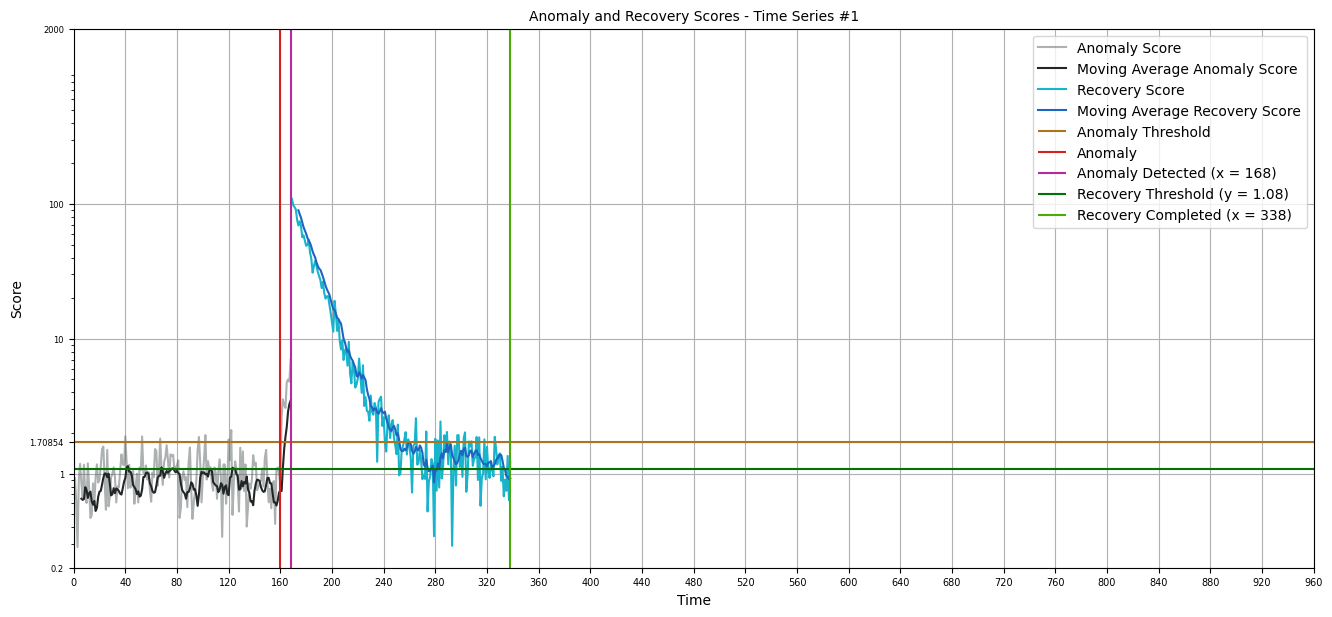

TS 1 completed. Anomaly Detected: True, Delay: 8, Process Recovered: True, Recovery Steps: 170


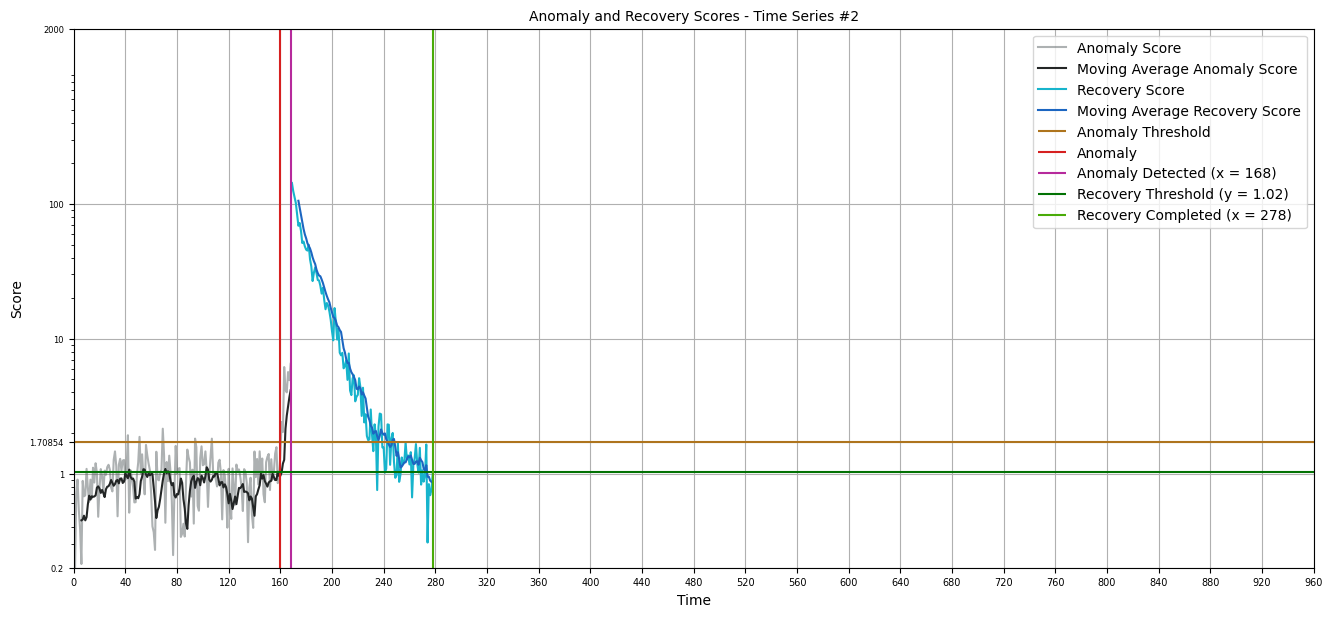

TS 2 completed. Anomaly Detected: True, Delay: 8, Process Recovered: True, Recovery Steps: 110


In [15]:
for ts_idx in ts_idx_list:
    hist_ts = df[ts_idx * n_samples_per_ts : (ts_idx + 1) * n_samples_per_ts]
    hist_ts = hist_ts.reset_index(drop=True)
    current_ts = pd.DataFrame(columns=hist_ts.columns)

    recovery_res_process_children = np.zeros((n_samples_per_ts, n_process_children))
    recovery_scores_process_children = np.full(n_samples_per_ts, np.nan)
    recovery_score_moving_averages = np.full(n_samples_per_ts, np.nan)

    anomaly_res_process_children = np.zeros((n_samples_per_ts, n_process_children))
    anomaly_scores_process_children = np.zeros(n_samples_per_ts)
    anomaly_score_moving_averages = np.zeros(n_samples_per_ts)

    n_consecutive_alarms = 0

    if with_plot:
        fig, ax, [
            recovery_score_line, recovery_moving_average_line, anomaly_score_line, anomaly_moving_average_line
        ] = initialize_fig(xmax, xticks, y_lims, yticks, anomaly_threshold, legend_loc, ts_idx)

        plt.close()
        dh_anomaly = display(fig, display_id=True)

    # --- Start detection process ---

    # Observe the process until max_lag
    for sample_idx in range(max_lag):
        new_sample = hist_ts.loc[sample_idx]
        current_ts.loc[sample_idx] = new_sample
        recovery_res_process_children[sample_idx] = np.nan
        recovery_scores_process_children[sample_idx] = np.nan
        recovery_score_moving_averages[sample_idx] = np.nan
        anomaly_res_process_children[sample_idx] = np.nan
        anomaly_scores_process_children[sample_idx] = np.nan
        anomaly_score_moving_averages[sample_idx] = np.nan

        if with_plot:
            update_fig(
                [anomaly_score_line, anomaly_moving_average_line],
                [anomaly_scores_process_children, anomaly_score_moving_averages],
                sample_idx
            )
            dh_anomaly.update(fig)

    # Start calculating residuals until max_lag + window - 1
    for sample_idx in range(max_lag, max_lag + window - 1):
        new_sample = hist_ts.loc[sample_idx]
        current_ts.loc[sample_idx] = new_sample
        recovery_res_process_children[sample_idx] = np.nan
        recovery_scores_process_children[sample_idx] = np.nan
        recovery_score_moving_averages[sample_idx] = np.nan
        anomaly_score_moving_averages[sample_idx] = np.nan

        for child, parents in process_child_parents_pairs.items():
            beta = child_beta_pairs[child]
            y_pred = forecast(current_ts, child, parents, beta, max_lag)

            y_true = new_sample[child]
            res = y_true - y_pred
            anomaly_res_process_children[sample_idx, process_children.index(child)] = res

        res_vector = anomaly_res_process_children[sample_idx, :]
        score = 1 / n_process_children * res_vector.T @ sample_precision @ res_vector
        anomaly_scores_process_children[sample_idx] = score

        if with_plot:
            update_fig(
                [anomaly_score_line, anomaly_moving_average_line],
                [anomaly_scores_process_children, anomaly_score_moving_averages],
                sample_idx
            )
            dh_anomaly.update(fig)
        
    sample_idx += 1
    if with_plot:
        ylim = ax.get_ylim()

    # Start calculating moving average as well and check for anomaly detection
    while (n_consecutive_alarms < consecutive_alarms_threshold) and (sample_idx < n_samples_per_ts):
        new_sample = hist_ts.loc[sample_idx]
        current_ts.loc[sample_idx] = new_sample
        recovery_res_process_children[sample_idx] = np.nan
        recovery_scores_process_children[sample_idx] = np.nan
        recovery_score_moving_averages[sample_idx] = np.nan

        for child, parents in process_child_parents_pairs.items():
            beta = child_beta_pairs[child]
            y_pred = forecast(current_ts, child, parents, beta, max_lag)

            y_true = new_sample[child]
            res = y_true - y_pred
            anomaly_res_process_children[sample_idx, process_children.index(child)] = res

        res_vector = anomaly_res_process_children[sample_idx, :]
        score = 1 / n_process_children * res_vector.T @ sample_precision @ res_vector
        score_moving_average = 1 / window * np.sum(anomaly_scores_process_children[sample_idx - window  + 1: sample_idx + 1])
        anomaly_scores_process_children[sample_idx] = score
        anomaly_score_moving_averages[sample_idx] = score_moving_average

        if sample_idx == 160:
            if with_plot:
                ax.vlines(160, ymin=ylim[0], ymax=ylim[1], color="#D62020", label="Anomaly")
                ax.legend(loc=legend_loc)

        if score_moving_average > anomaly_threshold:
            n_consecutive_alarms += 1
        else:
            n_consecutive_alarms = 0

        if n_consecutive_alarms == consecutive_alarms_threshold:
            if with_plot:
                ax.vlines(sample_idx, ymin=ylim[0], ymax=ylim[1], color="#B62A9C", label="Anomaly Detected (x = {})".format(sample_idx))
                ax.legend(loc=legend_loc)

        if with_plot:
            update_fig(
                [anomaly_score_line, anomaly_moving_average_line],
                [anomaly_scores_process_children, anomaly_score_moving_averages],
                sample_idx
            )
            dh_anomaly.update(fig)

        sample_idx += 1

    if n_consecutive_alarms == consecutive_alarms_threshold:
        anomaly_detected = True
        delay = sample_idx - 161
    else:
        anomaly_detected = False
        delay = np.nan
        process_recovered = False
        recovery_steps = np.nan

    if anomaly_detected:

        # --- Start recovery process ---

        if with_plot:
            recovery_score_line.set_label("Recovery Score")
            recovery_moving_average_line.set_label("Moving Average Recovery Score")

        # Calculate G, A, B matrices
        g = compute_g_matrix(
            hist_ts,
            manipulated_parents_pairs,
            process_child_parents_pairs,
            child_beta_pairs,
            process_children,
            manipulated,
            horizon
        )
        a, b = compute_a_b_matrices(n_manipulated, horizon)

        # Simulate healthy process

        idx_first_intervention = sample_idx
        idx_estimated_anomalous_score_start = sample_idx - consecutive_alarms_threshold - window + 1

        sample_cov = np.linalg.inv(sample_precision)

        rng = np.random.default_rng(0)

        healthy_ts = pd.DataFrame(columns=hist_ts.columns)

        for idx in range(idx_estimated_anomalous_score_start - max_lag, idx_estimated_anomalous_score_start):
            healthy_ts.loc[idx] = current_ts.loc[idx]

        for idx in range(idx_estimated_anomalous_score_start, sample_idx):
            healthy_ts.loc[idx, process_root] = current_ts.loc[idx, process_root]

            for child, parents in manipulated_parents_pairs.items():
                beta = child_beta_pairs[child]
                y_pred = forecast(healthy_ts, child, parents, beta, max_lag)
                healthy_ts.loc[idx, child] = y_pred

            for child, parents in process_child_parents_pairs.items():
                beta = child_beta_pairs[child]
                y_pred = forecast(healthy_ts, child, parents, beta, max_lag)
                healthy_ts.loc[idx, child] = y_pred

        n_consecutive_healthy_states = 0
        recovery_threshold = np.quantile(anomaly_score_moving_averages[max_lag + window - 1 : idx_estimated_anomalous_score_start], quantile_recovery_threshold)
        
        if with_plot:
            ax.hlines(recovery_threshold, xmin=0.0, xmax=xmax, colors="#027204", label="Recovery Threshold (y = {:.2f})".format(recovery_threshold))
            ax.legend(loc=legend_loc)

        while (n_consecutive_healthy_states < consecutive_healthy_threshold) and (sample_idx < n_samples_per_ts):

            # Calculate p_diff^c

            healthy_hat_ts = healthy_ts.loc[sample_idx - max_lag:].copy()

            for idx in range(sample_idx, sample_idx + horizon):
                healthy_hat_ts.loc[idx, process_root] = healthy_ts.loc[sample_idx - 1, process_root]

                for child, parents in manipulated_parents_pairs.items():
                    beta = child_beta_pairs[child]
                    y_pred = forecast(healthy_hat_ts, child, parents, beta, max_lag)
                    healthy_hat_ts.loc[idx, child] = y_pred

                for child, parents in process_child_parents_pairs.items():
                    beta = child_beta_pairs[child]
                    y_pred = forecast(healthy_hat_ts, child, parents, beta, max_lag)
                    healthy_hat_ts.loc[idx, child] = y_pred
            
            current_ts_tilde = current_ts.loc[sample_idx - max_lag:].copy()

            for idx in range(sample_idx, sample_idx + horizon):
                current_ts_tilde.loc[idx, process_root] = current_ts.loc[sample_idx - 1, process_root]
                current_ts_tilde.loc[idx, manipulated] = 0.0

                for child, parents in process_child_parents_pairs.items():
                    beta = child_beta_pairs[child]
                    y_pred = forecast(current_ts_tilde, child, parents, beta, max_lag)
                    current_ts_tilde.loc[idx, child] = y_pred

            process_child_diff = (current_ts_tilde.loc[sample_idx:, process_children] - healthy_hat_ts.loc[sample_idx:, process_children])
            process_child_diff = process_child_diff.to_numpy().reshape(-1)

            # --- Solve Quadratic Programming Problem ---

            m_last = current_ts.loc[sample_idx - 1, manipulated].to_numpy()

            q = 2 * (g.T @ g + lambda_w * a)
            c = 2 * (g.T @ process_child_diff - lambda_w * b.T @ m_last)

            m = np.linalg.solve(q, -c)
            m_new = pd.Series(m[:n_manipulated], index=manipulated)

            new_sample = hist_ts.loc[sample_idx]
            current_ts.loc[sample_idx, process_root] = new_sample[process_root]
            current_ts.loc[sample_idx, manipulated] = m_new

            healthy_ts.loc[sample_idx, process_root] = new_sample[process_root]
            for child, parents in manipulated_parents_pairs.items():
                beta = child_beta_pairs[child]
                healthy_ts.loc[sample_idx, child] = forecast(healthy_ts, child, parents, beta, max_lag)

            noise_vector = rng.multivariate_normal(
                mean=np.zeros(n_process_children),
                cov=sample_cov,
            )
            
            for child_idx, child in enumerate(process_children):
                parents = process_child_parents_pairs[child]
                beta = child_beta_pairs[child]
                
                y_pred = forecast(current_ts, child, parents, beta, max_lag)
                current_ts.loc[sample_idx, child] = y_pred
                y_simulated = y_pred + noise_vector[child_idx] # Add noise to the predicted value to simulate the stochastic nature of the process

                
                y_pred_healthy = forecast(healthy_ts, child, parents, beta, max_lag)
                healthy_ts.loc[sample_idx, child] = y_pred_healthy
            
                # Calculate the residual (difference between our simulated process and the healthy target)
                res = y_simulated - y_pred_healthy
                recovery_res_process_children[sample_idx, process_children.index(child)] = res

                y_pred_anomaly = forecast(hist_ts.loc[:sample_idx], child, parents, beta, max_lag)
            
                anomaly_res = new_sample[child] - y_pred_anomaly
                anomaly_res_process_children[sample_idx, process_children.index(child)] = anomaly_res

            res_vector = recovery_res_process_children[sample_idx, :]
            score = 1 / n_process_children * res_vector.T @ sample_precision @ res_vector
            recovery_scores_process_children[sample_idx] = score

            if sample_idx >= idx_first_intervention + window - 1:
                score_moving_average = 1 / window * np.sum(recovery_scores_process_children[sample_idx - window  + 1: sample_idx + 1])
            else:
                score_moving_average = np.nan
            recovery_score_moving_averages[sample_idx] = score_moving_average

            anomaly_res_vector = anomaly_res_process_children[sample_idx, :]
            anomaly_score = 1 / n_process_children * anomaly_res_vector.T @ sample_precision @ anomaly_res_vector
            anomaly_scores_process_children[sample_idx] = anomaly_score
            anomaly_score_moving_average = 1 / window * np.sum(anomaly_scores_process_children[sample_idx - window  + 1: sample_idx + 1])
            anomaly_score_moving_averages[sample_idx] = anomaly_score_moving_average

            if score_moving_average < recovery_threshold:
                n_consecutive_healthy_states += 1
            else:
                n_consecutive_healthy_states = 0

            if n_consecutive_healthy_states == consecutive_healthy_threshold:
                if with_plot:
                    ax.vlines(sample_idx, ymin=ylim[0], ymax=ylim[1], color="#49AB08", label="Recovery Completed (x = {})".format(sample_idx))
                    ax.legend(loc=legend_loc)

            if with_plot:
                update_fig(
                    [recovery_score_line, recovery_moving_average_line],
                    [recovery_scores_process_children, recovery_score_moving_averages],
                    sample_idx
                )
                dh_anomaly.update(fig)

            sample_idx += 1

        if n_consecutive_healthy_states == consecutive_healthy_threshold:
            process_recovered = True
            recovery_steps = sample_idx - idx_first_intervention
        else:
            process_recovered = False
            recovery_steps = np.nan

    results_df.loc[len(results_df)] = [ts_idx + 1, anomaly_detected, delay, process_recovered, recovery_steps]
    
    print(f"TS {ts_idx + 1} completed. Anomaly Detected: {anomaly_detected}, Delay: {delay}, Process Recovered: {process_recovered}, Recovery Steps: {recovery_steps}")
    results_df.to_csv(results_dir + "detection_recovery_results.csv", index=False)

In [16]:
anomaly_dection_rate = len(results_df[results_df["Anomaly Detected"] == 1]) / len(results_df)
median_delay = results_df["Delay"].median()
process_recovery_rate = len(results_df[results_df["Process Recovered"] == 1]) / len(results_df)
median_recovery_steps = results_df["Recovery Steps"].median()

print(f"Anomaly Detection Rate: {anomaly_dection_rate:.2%}")
print(f"Median Delay: {median_delay}")
print(f"Process Recovery Rate: {process_recovery_rate:.2%}")
print(f"Median Recovery Steps: {median_recovery_steps}")

Anomaly Detection Rate: 100.00%
Median Delay: 8.0
Process Recovery Rate: 100.00%
Median Recovery Steps: 140.0


# 2. Statistics of the Final Results

In [17]:
final_results_file = "detection_recovery_results_all.csv"

df_final_results = pd.read_csv(results_dir + final_results_file)

df_final_results_anomaly_detected = df_final_results[df_final_results["Anomaly Detected"]]
n_anomaly_detected_ts = len(df_final_results_anomaly_detected)

df_final_results_anomaly_detected_recovery_successful = df_final_results_anomaly_detected[
    df_final_results_anomaly_detected["Process Recovered"]
]
n_recovered_ts = len(df_final_results_anomaly_detected_recovery_successful)

recovery_rate = n_recovered_ts / n_anomaly_detected_ts

median_recovery_time = np.median(df_final_results_anomaly_detected_recovery_successful["Recovery Steps"])

print("Process Recovery:")
print(f"Recovery Rate: {recovery_rate * 100} %")
print(f"Median Time for Recovery: {median_recovery_time} steps")

Process Recovery:
Recovery Rate: 99.45587887390585 %
Median Time for Recovery: 255.0 steps
